In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import warnings
warnings.filterwarnings('ignore')

# EDA

In [2]:
df=pd.read_excel("dataset.xlsx")

In [3]:
df

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."
...,...,...,...
1435,Excellent mobile,5,Excellent mobile
1436,Never expected from samsung,1,"All over mobile performance is very poor, neve..."
1437,Good value for money,5,Battery life is good but camera clarity could ...
1438,Unreal and whitish display,1,"It's a very bad product, highly dissatisfied....."


In [4]:
df.head()

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   1440 non-null   object
 1   rating  1440 non-null   int64 
 2   body    1440 non-null   object
dtypes: int64(1), object(2)
memory usage: 33.9+ KB


In [6]:
df.columns

Index(['title', 'rating', 'body'], dtype='object')

In [7]:
# Removing empty and Non English Reviews

In [8]:
df=df[df['body'].str.strip() != ""]

In [9]:
df =df[df['body'].str.contains(r'[a-zA-Z]', regex=True)]

In [10]:
# checking for null values
df.isnull().sum()

title     0
rating    0
body      0
dtype: int64

In [11]:
# checking for duplicates
df.duplicated().sum()

np.int64(0)

In [12]:
df.shape

(1437, 3)

In [13]:
df.describe()

,rating
count,1437.000000
mean,3.178149
std,1.582986
min,1.000000
25%,1.000000
50%,4.000000
75%,5.000000
max,5.000000


In [14]:
# cleaning Data

In [15]:
import spacy
nlp = spacy.load("en_core_web_sm")
import re
from nltk.tokenize import word_tokenize,sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.stem.porter import PorterStemmer
import string
from nltk.corpus import stopwords

In [16]:
import re

# removing stop words
# Keep important negation words

custom_stopwords = set(stopwords.words('english'))
custom_stopwords = custom_stopwords - {"not","no","never","nor"}

def clean_text(text):
    text = str(text).lower()# Convert to lowercase
    text = re.sub(r'http\\S+|www\\S+', '', text) # Remove links
    text = re.sub(r'\\d+', '', text) # Remove numbers
    
    # SpaCy processing
    doc = nlp(text)
    tokens = [token.lemma_
        for token in doc
        if token.text not in custom_stopwords
        and not token.is_punct
        and token.is_alpha
    ]

    return " ".join(tokens)

df['clean_review'] = df['body'].apply(clean_text)

In [17]:
df['word_count'] = df['clean_review'].apply(lambda x: len(x.split()))
df['word_count'].describe()

count    1437.000000
mean       28.968685
std        20.862656
min         1.000000
25%        17.000000
50%        24.000000
75%        35.000000
max       246.000000
Name: word_count, dtype: float64

In [18]:
# Bar chart

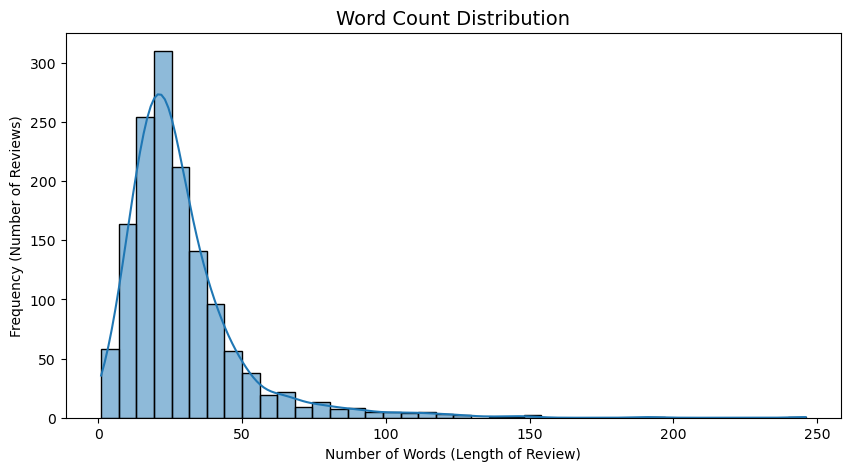

In [19]:
import seaborn as sns
plt.figure(figsize=(10,5))
sns.histplot(df['word_count'], bins=40, kde=True)
plt.title("Word Count Distribution", fontsize=14)
plt.xlabel("Number of Words (Length of Review)")
plt.ylabel("Frequency (Number of Reviews)")

plt.show()

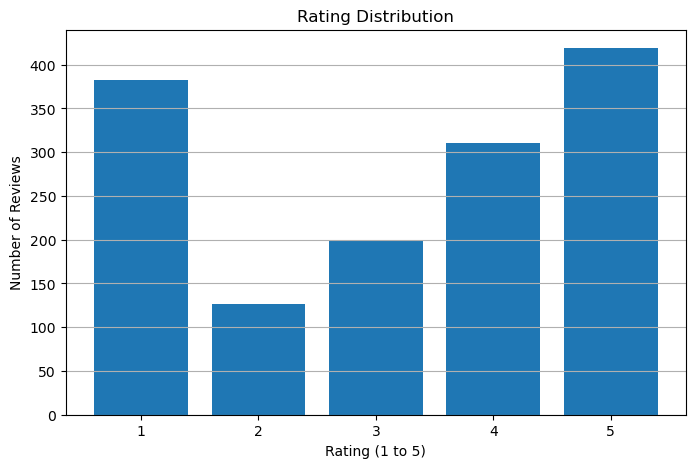

In [20]:
# Count ratings
rating_counts = df['rating'].value_counts().sort_index()
plt.figure(figsize=(8,5))
plt.bar(rating_counts.index, rating_counts.values)
plt.title("Rating Distribution")
plt.xlabel("Rating (1 to 5)")                 # X-axis → categories
plt.ylabel("Number of Reviews")               # Y-axis → frequency
plt.xticks([1,2,3,4,5])                       # show all ratings clearly
plt.grid(axis='y')
plt.show()

In [21]:
def get_sentiment(rating):
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

df['sentiment'] = df['rating'].apply(get_sentiment)

In [22]:
df['sentiment'].value_counts()

sentiment
Positive    729
Negative    509
Neutral     199
Name: count, dtype: int64

In [23]:

# CLASS DISTRIBUTION
print("\nPercentage Distribution\n")
print(
    df['sentiment'].value_counts(normalize=True) * 100
)


Percentage Distribution

sentiment
Positive    50.730689
Negative    35.421016
Neutral     13.848295
Name: proportion, dtype: float64


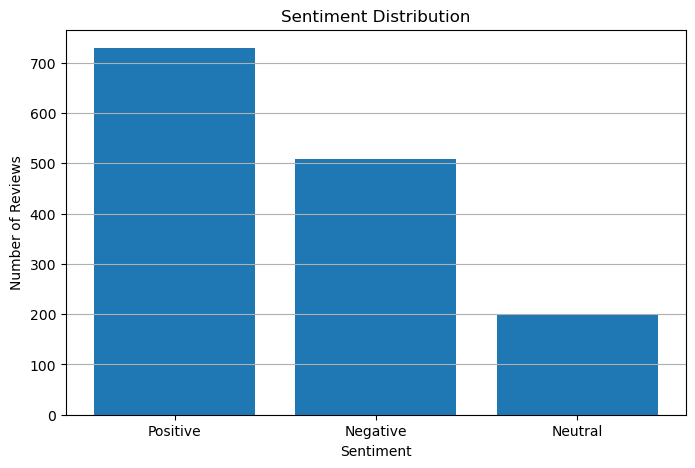

In [24]:
# bar chart
sentiment_counts = df['sentiment'].value_counts()
plt.figure(figsize=(8,5))
plt.bar(sentiment_counts.index, sentiment_counts.values)
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")                      # X-axis → categories
plt.ylabel("Number of Reviews")              # Y-axis → frequency
plt.grid(axis='y')
plt.show()

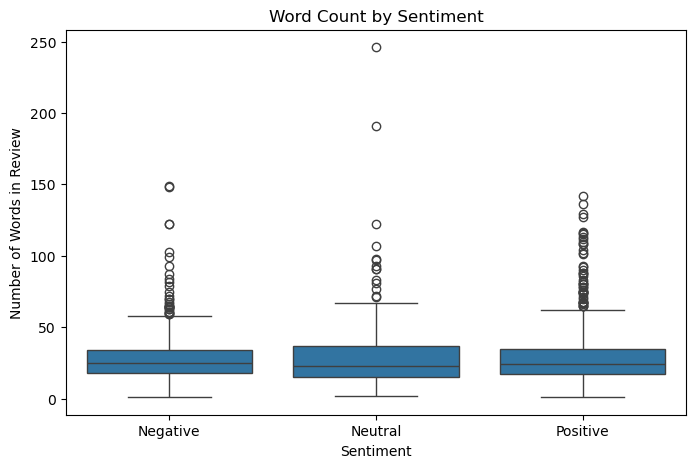

In [25]:
#box plot
plt.figure(figsize=(8,5))
sns.boxplot(x='sentiment', y='word_count', data=df)
plt.title("Word Count by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words in Review")
plt.show()

In [26]:
from collections import Counter

all_words = " ".join(df['clean_review']).split()
common_words = Counter(all_words).most_common(25)
print(common_words)

[('phone', 1568), ('good', 1257), ('not', 1251), ('camera', 873), ('battery', 724), ('samsung', 630), ('quality', 610), ('use', 526), ('mobile', 519), ('buy', 418), ('price', 339), ('day', 332), ('well', 320), ('product', 315), ('also', 303), ('like', 291), ('get', 285), ('life', 281), ('display', 266), ('work', 265), ('no', 258), ('bad', 254), ('one', 232), ('screen', 225), ('time', 211)]


In [27]:
for sentiment in df['sentiment'].unique():
    subset = df[df['sentiment'] == sentiment]
    words = " ".join(subset['clean_review']).split()
    
    print(f"\nTop words in {sentiment}:")
    print(Counter(words).most_common(10))


Top words in Negative:
[('phone', 574), ('not', 546), ('samsung', 289), ('mobile', 252), ('buy', 226), ('camera', 215), ('quality', 194), ('bad', 194), ('product', 169), ('amazon', 151)]

Top words in Neutral:
[('not', 257), ('phone', 233), ('good', 167), ('camera', 141), ('quality', 105), ('battery', 95), ('mobile', 85), ('samsung', 81), ('use', 79), ('well', 56)]

Top words in Positive:
[('good', 943), ('phone', 761), ('camera', 517), ('battery', 489), ('not', 448), ('quality', 311), ('use', 298), ('samsung', 260), ('price', 241), ('life', 202)]


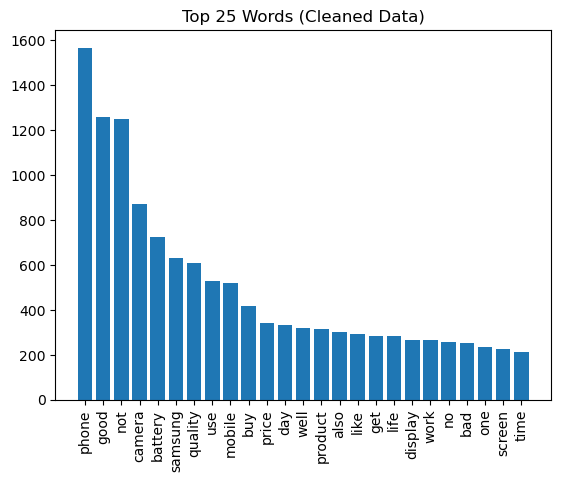

In [28]:
words = [w[0] for w in common_words]
counts = [w[1] for w in common_words]

plt.bar(words, counts)
plt.xticks(rotation=90)
plt.title("Top 25 Words (Cleaned Data)")
plt.show()

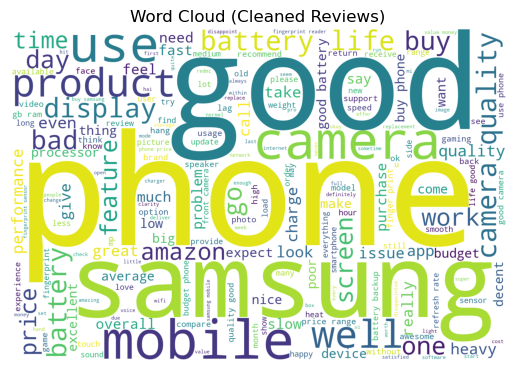

In [29]:
from wordcloud import WordCloud

text = " ".join(df['clean_review'])
wc = WordCloud(width=1500, height=1000, background_color='white').generate(text)
plt.imshow(wc)
plt.axis("off")
plt.title("Word Cloud (Cleaned Reviews)")
plt.show()

# Model Building 

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer
# TF-IDF VECTORIZATION
tfidf = TfidfVectorizer(max_features=10000,ngram_range=(1,2),min_df=2,max_df=0.90,sublinear_tf=True,strip_accents='unicode')
# Transform text
X = tfidf.fit_transform(df['clean_review'])
# Shape
print("TF-IDF Shape :", X.shape)

TF-IDF Shape : (1437, 6114)


In [31]:
from sklearn.model_selection import train_test_split
# Spliting of data
X_train, X_test, y_train, y_test = train_test_split(X, df['sentiment'], test_size=0.2, random_state=42)
print(X_train.shape)
print(X_test.shape)

(1149, 6114)
(288, 6114)


In [32]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)

# logistic Regression

In [33]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=2000,class_weight='balanced')
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)
# evaluation
print("Train Accuracy:")
print(lr_model.score(X_train, y_train)*100)
print("Test Accuracy:")
print(lr_model.score(X_test, y_test)*100)

Train Accuracy:
96.60574412532638
Test Accuracy:
75.69444444444444


In [34]:
# Evaluation metrics
print(classification_report(y_test, y_pred_lr))
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test,y_pred_lr,average='weighted')
lr_recall = recall_score(y_test,y_pred_lr,average='weighted')
lr_f1 = f1_score(y_test,y_pred_lr,average='weighted')
print("Accuracy  :",lr_accuracy)
print("Precision :",lr_precision)
print("Recall    :",lr_recall)
print("F1-Score  :",lr_f1)

              precision    recall  f1-score   support

    Negative       0.80      0.79      0.80       107
     Neutral       0.33      0.32      0.32        38
    Positive       0.83      0.85      0.84       143

    accuracy                           0.76       288
   macro avg       0.65      0.65      0.65       288
weighted avg       0.75      0.76      0.76       288

Accuracy  : 0.7569444444444444
Precision : 0.7534105975321406
Recall    : 0.7569444444444444
F1-Score  : 0.755094895812036


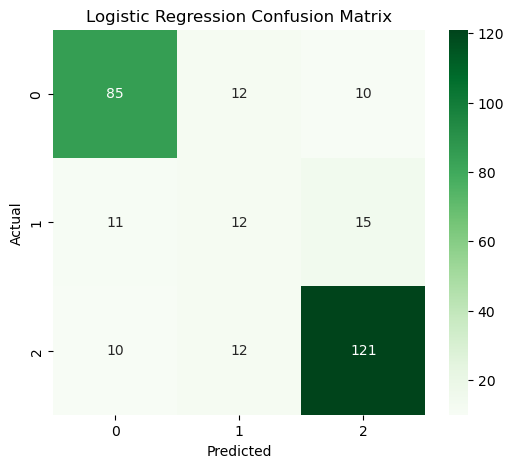

In [35]:
#confusion matrix
cm = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Random Forest

In [36]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
# evaluation
print("Train Accuracy:")
print(rf_model.score(X_train, y_train)*100)
print("Test Accuracy:")
print(rf_model.score(X_test, y_test)*100)

Train Accuracy:
100.0
Test Accuracy:
75.0


In [37]:
#Evaluation metrics
print(classification_report(y_test, y_pred_rf))
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test,y_pred_rf,average='weighted')
rf_recall = recall_score(y_test,y_pred_rf,average='weighted')
rf_f1 = f1_score(y_test,y_pred_rf,average='weighted')
print("Accuracy  :", rf_accuracy)
print("Precision :", rf_precision)
print("Recall    :", rf_recall)
print("F1-Score  :", rf_f1)

              precision    recall  f1-score   support

    Negative       0.82      0.73      0.77       107
     Neutral       0.00      0.00      0.00        38
    Positive       0.72      0.97      0.82       143

    accuracy                           0.75       288
   macro avg       0.51      0.56      0.53       288
weighted avg       0.66      0.75      0.69       288

Accuracy  : 0.75
Precision : 0.6600740841741659
Recall    : 0.75
F1-Score  : 0.6947845454188276


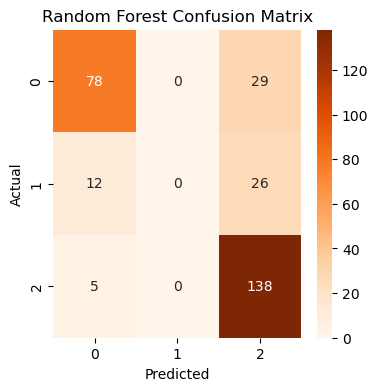

In [38]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(4,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Oranges'
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Naive Bayes

In [39]:
from sklearn.naive_bayes import MultinomialNB
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)
# evaluation
print("Train Accuracy:")
print(nb_model.score(X_train, y_train)*100)
print("Test Accuracy:")
print(nb_model.score(X_test, y_test)*100)

Train Accuracy:
80.67885117493474
Test Accuracy:
73.95833333333334


In [40]:
# Evaluation Metrics
print("\nNAIVE BAYES ")
print(classification_report(y_test, y_pred_nb))
nb_accuracy = accuracy_score(y_test, y_pred_nb)
nb_precision = precision_score(y_test,y_pred_nb,average='weighted')
nb_recall = recall_score(y_test,y_pred_nb,average='weighted')
nb_f1 = f1_score(y_test,y_pred_nb,average='weighted')
print("Accuracy  :", nb_accuracy)
print("Precision :", nb_precision)
print("Recall    :", nb_recall)
print("F1-Score  :", nb_f1)


NAIVE BAYES 
              precision    recall  f1-score   support

    Negative       0.89      0.67      0.77       107
     Neutral       0.00      0.00      0.00        38
    Positive       0.68      0.99      0.81       143

    accuracy                           0.74       288
   macro avg       0.52      0.55      0.52       288
weighted avg       0.67      0.74      0.68       288

Accuracy  : 0.7395833333333334
Precision : 0.6684614868491681
Recall    : 0.7395833333333334
F1-Score  : 0.6846339918946303


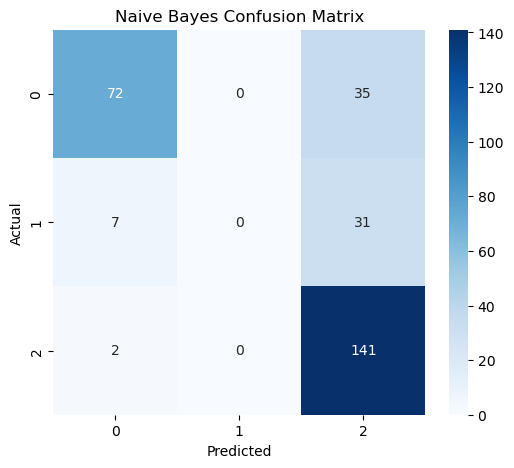

In [41]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# SVC

In [42]:
from sklearn.svm import LinearSVC
svc_model = LinearSVC(C=1,class_weight='balanced')
svc_model.fit(X_train, y_train)
y_pred_svc = svc_model.predict(X_test)
# evaluation
print("Train Accuracy:")
print(svc_model.score(X_train, y_train)*100)
print("Test Accuracy:")
print(svc_model.score(X_test, y_test)*100)

Train Accuracy:
99.91296779808529
Test Accuracy:
75.34722222222221


In [43]:
# Evaluation metrics
print(classification_report(y_test, y_pred_svc))
svc_accuracy = accuracy_score(y_test, y_pred_svc)
svc_precision = precision_score(y_test,y_pred_svc,average='weighted')
svc_recall = recall_score(y_test,y_pred_svc,average='weighted')
svc_f1 = f1_score(y_test,y_pred_svc,average='weighted')
print("Accuracy  :", svc_accuracy)
print("Precision :", svc_precision)
print("Recall    :", svc_recall)
print("F1-Score  :",svc_f1)

              precision    recall  f1-score   support

    Negative       0.77      0.77      0.77       107
     Neutral       0.32      0.21      0.25        38
    Positive       0.81      0.89      0.85       143

    accuracy                           0.75       288
   macro avg       0.63      0.62      0.62       288
weighted avg       0.73      0.75      0.74       288

Accuracy  : 0.7534722222222222
Precision : 0.7312803616018374
Recall    : 0.7534722222222222
F1-Score  : 0.7399621649650991


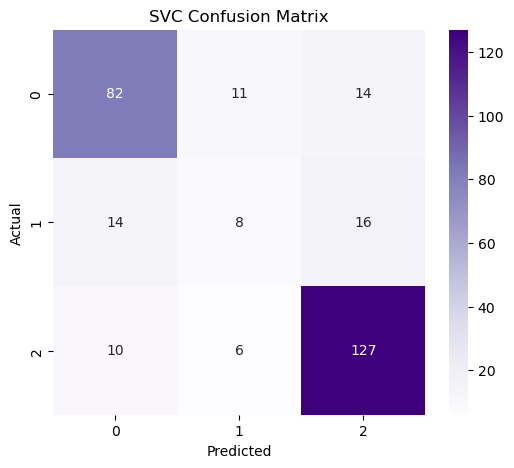

In [45]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred_svc)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Purples'
)
plt.title("SVC Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Model Comparision

In [46]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Naive Bayes',
        'SVC'
    ],
    'Accuracy': [lr_accuracy,rf_accuracy,nb_accuracy,svc_accuracy],
    "Precision": [lr_precision,rf_precision,nb_precision,svc_precision],
    "Recall": [lr_recall,rf_recall,nb_recall,svc_recall],
    "F1-Score": [lr_f1,rf_f1,nb_f1,svc_f1]

})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.756944,0.753411,0.756944,0.755095
1,Random Forest,0.750000,0.660074,0.750000,0.694785
2,Naive Bayes,0.739583,0.668461,0.739583,0.684634
3,SVC,0.753472,0.731280,0.753472,0.739962


# Hyperparameter Tuning

In [47]:
from sklearn.model_selection import GridSearchCV

models = {
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=2000),
        "params": {"C": [0.01, 0.1, 1, 5,10],'solver':['liblinear']}
    },
    "Random Forest": {
        "model": RandomForestClassifier(random_state=42),
        "params": {"n_estimators": [200, 300],"max_depth": [20, 30, None],
                  'min_samples_split': [2, 5],
                  'min_samples_leaf': [1, 2]}
    },
    "Naive Bayes": {
        "model": MultinomialNB(),
        "params": {"alpha": [0.1, 0.5, 1.0]}
    },
    "SVC": {
        "model": LinearSVC(),
        "params": {"C": [0.01, 0.1, 1, 5,10, 20 ],
                  'class_weight': [None, 'balanced']
                  }
    }
}
# STORE RESULTS
results = []
# LOOP THROUGH MODELS
for model_name, mp in models.items():
    print(f"Tuning {model_name}")
    # Grid Search
    grid = GridSearchCV(
        estimator=mp['model'],
        param_grid=mp['params'],
        cv=5,
        scoring='f1_weighted',
        n_jobs=-1
    )
    # Train
    grid.fit(X_train, y_train)
    # Best Model
    best_model = grid.best_estimator_
    # Predictions
    y_pred = best_model.predict(X_test)
    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test,y_pred,average='weighted')
    recall = recall_score(y_test,y_pred,average='weighted')
    f1 = f1_score(y_test,y_pred,average='weighted')
    
     # Print Results
    print("Best Parameters :", grid.best_params_)
    print("Best CV Score   :", grid.best_score_)
    results.append({
        "Model": model_name,
        "Best Parameters": grid.best_params_,
        "CV Score": grid.best_score_,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })
    # FINAL RESULTS TABLE
results_df = pd.DataFrame(results)
print("FINAL MODEL COMPARISON")
print(results_df) 


Tuning Logistic Regression
Best Parameters : {'C': 5, 'solver': 'liblinear'}
Best CV Score   : 0.7209211007344066
Tuning Random Forest
Best Parameters : {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
Best CV Score   : 0.6899151655923446
Tuning Naive Bayes
Best Parameters : {'alpha': 0.1}
Best CV Score   : 0.7003429582355334
Tuning SVC
Best Parameters : {'C': 0.1, 'class_weight': 'balanced'}
Best CV Score   : 0.7192255271934564
FINAL MODEL COMPARISON
                 Model                                    Best Parameters  \
0  Logistic Regression                    {'C': 5, 'solver': 'liblinear'}   
1        Random Forest  {'max_depth': None, 'min_samples_leaf': 1, 'mi...   
2          Naive Bayes                                     {'alpha': 0.1}   
3                  SVC             {'C': 0.1, 'class_weight': 'balanced'}   

   CV Score  Accuracy  Precision    Recall  F1-Score  
0  0.720921  0.763889   0.712983  0.763889  0.723587  
1  0.6899

In [48]:
# Deployment

In [52]:
import pickle

# Save tuned SVM model
pickle.dump(
    best_model,
    open('svc_sentiment_model.pkl', 'wb')
)

# Save TF-IDF vectorizer
pickle.dump(
    tfidf,
    open('tfidf_vectorizer.pkl', 'wb')
)

print("Files Saved")

Files Saved
